# Controls: L2 of the emitter's model against the distance to the nearest fish, correct vs wrong EODs

Good frames only (`good_frames_better_list.csv`): 3,501 EODs (2-fish) and 6,751 (3-fish). Four pipelines, the best of each kind:
- **my model**: numerical, voltage comparison $\lVert r - g_0 L_f^{0.25} m_f\rVert$ with the control's own $g_0$, at the EOD frame and at
  the best offset (−5 frames for 2-fish, −4 for 3-fish; $g_0$ refitted there);
- **Denis**: his analytic model with my mask midline, at the EOD frame and with the midlines taken from the same shifted frame
  (`EODAssignment/analysis/social_electric_fish_runners/denis_offset_runner_all.py`).

**L2** = distance between the *emitter's* (true fish's) predicted pattern and the recorded one, both scaled to max |v| = 1, so the two
models are on the same scale: mine = model × −1 vs the recorded peak-sample pattern (`v_rec`); Denis' = his normalized predicted vs
recorded signed peak-to-peak patterns (`silent_fish.pattern_l2`). It measures how well the true fish's model fits, whatever the
pipeline then picked. **Correct / wrong** = whether that pipeline gave the EOD to the emitter. **Distance** = smallest mask-edge
distance from the emitter to another fish in the EOD frame (`gap_cm`), the same for all pipelines.

8 bins with equal numbers of good-frame EODs per recording (same bins for every pipeline); points at the bin median distance (of all good-frame EODs in the bin), mean
± standard error; wrong-EOD points with fewer than 5 EODs are drawn hollow and the number of wrong EODs is written next to each.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

N, NBINS, MIN_N = 150, 8, 5
OUT = 'results/baseline_g0/l2_vs_distance'; os.makedirs(OUT, exist_ok=True)
REC = {
    '2-fish (2024-02-13)': dict(key='2-fish', res='results/eod_ground_truth', cache='conductivities/model_voltages_N150_sinks0and0.05_el46ee63_bem_a453a8.pkl',
                                emitter=1, letter='A', offset=-5, letters={'A': 1, 'B': 0}),
    '3-fish (2024-10-15)': dict(key='3-fish', res='results/eod_ground_truth_3fish', cache='conductivities/model_voltages_N150_sinks0and0.05_elc5c81b_bem_a453a8.pkl',
                                emitter=0, letter='C', offset=-4, letters={'A': 1, 'B': 2, 'C': 0}),
}
PIPES = {   # label: (column of picks_<rec>.csv, colour, marker, offset?)
    'my model (voltage, own g0)': ('numerical, voltage, own g0', '#F08A24', 's', False),
    'Denis (my mask midline)': ('analytic, mask midline', '#17A0B0', 'D', False),
    'my model (voltage, own g0), best offset': ('numerical, voltage, own g0, best offset', '#6B1A0C', 'v', True),
    'Denis (my mask midline), best offset': ('analytic, mask midline, best offset', '#0B4F8A', 'p', True),
}
unit = lambda x: x / np.abs(x).max(axis=-1, keepdims=True)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'grid.linewidth': 0.8, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b', 'xtick.color': '#5a5a55',
                     'ytick.color': '#5a5a55'})

## Per-EOD L2 of the emitter's model

In [2]:
D = {}
for name, c in REC.items():
    picks = pd.read_csv(f"results/baseline_g0/vs_distance/picks_{c['key']}.csv", index_col='row')
    cache = pd.read_pickle(f"{c['res']}/{c['cache']}")
    assert (cache.frame.to_numpy() == picks.Frame.to_numpy()).all()
    em = c['emitter']
    R = unit(np.stack(cache.v_rec.map(np.asarray)))
    M0 = -np.stack(cache.u_sink0.map(lambda u: np.asarray(u, float)))[:, em]
    U = pd.read_pickle(f"{c['res']}/conductivities/model_voltages_N{N}_sink0_bem_offset{c['offset']}.pkl")
    Mb = -np.stack([U[int(k)] for k in picks.Frame])[:, em]
    l2 = {'my model (voltage, own g0)': np.linalg.norm(unit(M0) - R, axis=1),
          'my model (voltage, own g0), best offset': np.linalg.norm(unit(Mb) - R, axis=1)}
    for lab, off in [('Denis (my mask midline)', 0), ('Denis (my mask midline), best offset', c['offset'])]:
        base = f"{c['res']}/conductivities/denis_mask_midline_offset"
        t = pd.read_csv(f'{base}/denis_mask_midline_all_eods_offset{off}.csv')
        assert (t.eod_row.to_numpy() == picks.index.to_numpy()).all()
        d = pd.read_pickle(next((__import__('pathlib').Path(base) / f'all_eods_offset{off:+d}').glob('Assigned_*.pkl')))
        has = t.pick.notna().to_numpy(); assert has.sum() == len(d)
        v = np.full(len(t), np.nan)
        v[has] = np.linalg.norm(np.stack(d[f"normalized_predicted_PTP_{c['letter']}"]) - np.stack(d['normalized_recorded_PTP']), axis=1)
        l2[lab] = v
        same = (t.pick.map(c['letters']).where(has).to_numpy() == picks[PIPES[lab][0]].to_numpy()) | ~has
        assert same.all(), lab                                       # same picks as the accuracy plots
    good = picks['better list'].to_numpy()
    T = pd.DataFrame({'gap_cm': picks.gap_cm}, index=picks.index)[good]
    for lab, (col, *_ ) in PIPES.items():
        T[f'L2 | {lab}'] = l2[lab][good]; T[f'correct | {lab}'] = (picks[col] == em).to_numpy()[good]
    T.to_csv(f"{OUT}/l2_emitter_good_frames_{c['key']}.csv")
    D[name] = T
    print(name, len(T), 'good-frame EODs;', ', '.join(f"{lab}: {int((~T[f'correct | {lab}']).sum())} wrong" for lab in PIPES))

2-fish (2024-02-13) 3501 good-frame EODs; my model (voltage, own g0): 100 wrong, Denis (my mask midline): 106 wrong, my model (voltage, own g0), best offset: 23 wrong, Denis (my mask midline), best offset: 31 wrong


3-fish (2024-10-15) 6751 good-frame EODs; my model (voltage, own g0): 165 wrong, Denis (my mask midline): 324 wrong, my model (voltage, own g0), best offset: 78 wrong, Denis (my mask midline), best offset: 76 wrong


## Mean L2 against distance, correct vs wrong
Left: at the EOD frame; right: at the best offset. Solid = correctly assigned EODs, dashed = wrongly assigned.

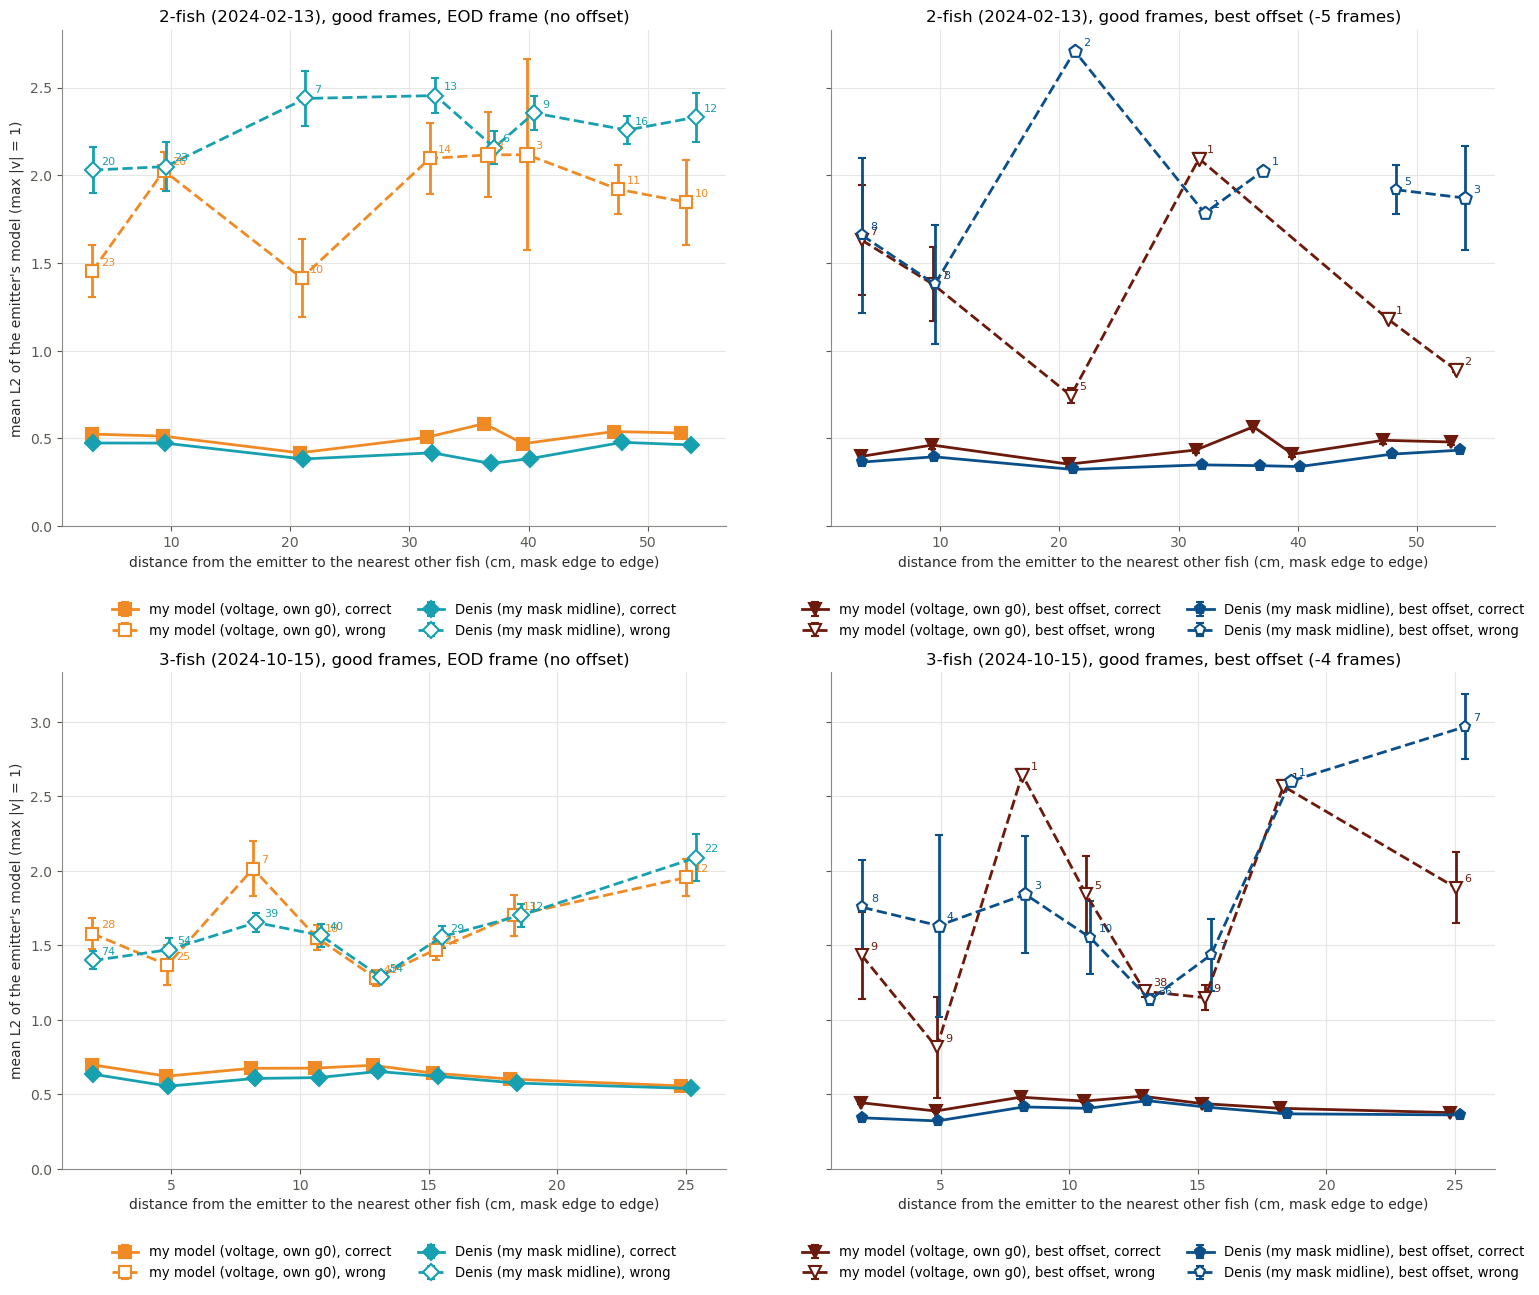

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(16, 13), sharey='row')
rows = []
for row, (name, T) in zip(axs, D.items()):
    T = T.dropna(subset=['gap_cm'])
    bins = pd.qcut(T.gap_cm, NBINS, duplicates='drop')
    xmed = T.gap_cm.groupby(bins, observed=True).median()                 # every curve at the bin median of all good-frame EODs
    for a, offset in zip(row, (False, True)):
        labs = [l for l, p in PIPES.items() if p[3] == offset]
        for j, lab in enumerate(labs):
            col, c, mk, _ = PIPES[lab]
            for ok, ls, fill in ((True, '-', True), (False, '--', False)):
                sub = T[T[f'correct | {lab}'] == ok]
                g = sub.groupby(bins.loc[sub.index], observed=True)
                y = g[f'L2 | {lab}'].mean(); se = g[f'L2 | {lab}'].sem(); n = g.size(); x = xmed.loc[y.index]
                xs = x.to_numpy() * (1 + 0.015 * (j - 0.5) + (0.008 if not ok else 0))
                a.errorbar(xs, y, yerr=se, color=c, ls=ls, lw=2, marker=mk, ms=8, capsize=3, mew=1.5,
                           mfc=c if ok else 'white', mec=c, label=f"{lab}, {'correct' if ok else 'wrong'}")
                if not ok:
                    for xx, yy, nn in zip(xs, y, n):
                        a.annotate(str(nn), (xx, yy), textcoords='offset points', xytext=(6, 4), fontsize=8, color=c)
                    few = n < MIN_N
                    a.scatter(xs[few.to_numpy()], y[few], s=90, facecolor='white', edgecolor=c, lw=1.5, marker=mk, zorder=5)
                rows.append(pd.DataFrame({'recording': name, 'pipeline': lab, 'assigned': 'correct' if ok else 'wrong',
                                          'median distance (cm)': x.to_numpy(), 'n EODs': n.to_numpy(),
                                          'mean L2': y.to_numpy(), 'SE': se.to_numpy()}))
        a.set(title=f"{name}, good frames, {'best offset (' + str(REC[name]['offset']) + ' frames)' if offset else 'EOD frame (no offset)'}",
              xlabel='distance from the emitter to the nearest other fish (cm, mask edge to edge)')
        a.legend(fontsize=9.5, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=2, frameon=False)
    row[0].set_ylabel("mean L2 of the emitter's model (max |v| = 1)"); row[0].set_ylim(bottom=0)
plt.tight_layout(); fig.savefig(f'{OUT}/l2_vs_distance_correct_wrong_good_frames.png', dpi=120); plt.show()
TAB = pd.concat(rows); TAB.to_csv(f'{OUT}/l2_vs_distance_correct_wrong_good_frames.csv', index=False)

## Overall mean L2 (good frames)

In [4]:
rows = []
for name, T in D.items():
    for lab in PIPES:
        for ok in (True, False):
            v = T.loc[T[f'correct | {lab}'] == ok, f'L2 | {lab}']
            rows.append({'recording': name, 'pipeline': lab, 'assigned': 'correct' if ok else 'wrong', 'n EODs': len(v),
                         'mean L2': v.mean(), 'SE': v.sem(), 'median L2': v.median()})
S = pd.DataFrame(rows); S.to_csv(f'{OUT}/l2_overall_correct_wrong_good_frames.csv', index=False)
display(S.pivot_table(index='pipeline', columns=['recording', 'assigned'], values=['mean L2', 'n EODs'], sort=False).round(3))

mean L2         \
recording                               2-fish (2024-02-13)          
assigned                                            correct  wrong   
pipeline                                                             
my model (voltage, own g0)                            0.511  1.819   
Denis (my mask midline)                               0.429  2.216   
my model (voltage, own g0), best offset               0.450  1.297   
Denis (my mask midline), best offset                  0.370  1.721   

                                                                    \
recording                               3-fish (2024-10-15)          
assigned                                            correct  wrong   
pipeline                                                             
my model (voltage, own g0)                            0.645  1.512   
Denis (my mask midline)                               0.599  1.516   
my model (voltage, own g0), best offset               0.434  1.302   
Denis (my mask midline), best offset                  0.385  1.525   

                                                     n EODs         \
recording                               2-fish (2024-02-13)          
assigned                                            correct  wrong   
pipeline                                                             
my model (voltage, own g0)                           3401.0  100.0   
Denis (my mask midline)                              3395.0  106.0   
my model (voltage, own g0), best offset              3478.0   23.0   
Denis (my mask midline), best offset                 3470.0   31.0   

                                                                    
recording                               3-fish (2024-10-15)         
assigned                                            correct  wrong  
pipeline                                                            
my model (voltage, own g0)                           6586.0  165.0  
Denis (my mask midline)                              6427.0  324.0  
my model (voltage, own g0), best offset              6673.0   78.0  
Denis (my mask midline), best offset                 6675.0   76.0